<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_9/tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS 1**

#### 1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt


data = pd.read_csv('voice.csv')
data.head()

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [3]:
# Menggunakan nilai k = 3
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [4]:
y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.9768664563617245
Confusion Matrix:
 [[440  12]
 [ 10 489]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.97      0.98       452
        male       0.98      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



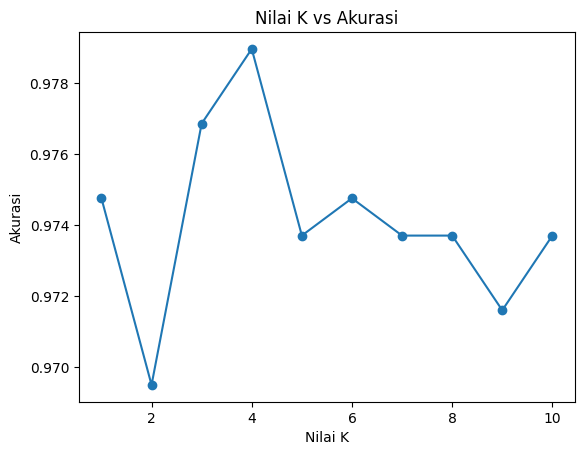

In [12]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

#### 2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

- Penjelasan Kode
  - Konversi Label Kategorikal<br>
  Mengubah variabel label bernilai teks (female dan male) menjadi nilai numerik ($0$ untuk female dan $1$ untuk male) agar dapat dihitung tingkat korelasinya.   
  - Perhitungan Korelasi<br> Fungsi data_encoded.corr() menghitung koefisien korelasi Pearson antar seluruh pasangan fitur numerik dalam dataset.
  - Visualisasi Heatmap<br>
  Fungsi sns.heatmap() dari perpustakaan Seaborn menampilkan matriks korelasi dalam bentuk peta warna. Nilai cmap='coolwarm' membedakan korelasi positif (warna merah) dan korelasi negatif (warna biru).  

- Penjelasan Hasil Visualisasi
  - Skala Warna Korelasi<br>
  Rentang warna berada di angka 1.00 hingga -0.75. Warna merah tua menunjukkan hubungan linier positif yang sangat kuat, sedangkan warna biru tua menunjukkan hubungan linier negatif yang kuat.   
  - Korelasi Terhadap Target (label)<br>
  Pada baris paling bawah (label), variabel meanfun (frekuensi fundamental rata-rata) memiliki warna biru paling gelap dibandingkan fitur lainnya. Hal ini menunjukkan bahwa meanfun memiliki hubungan korelasi negatif yang paling signifikan terhadap penentuan gender.
  - Multikolinearitas Antar Fitur<br>
  Beberapa fitur menunjukkan korelasi internal yang sangat kuat satu sama lain (kotak merah tua di luar diagonal utama), seperti pasangan fitur meanfreq dengan centroid, serta maxdom dengan dfrange

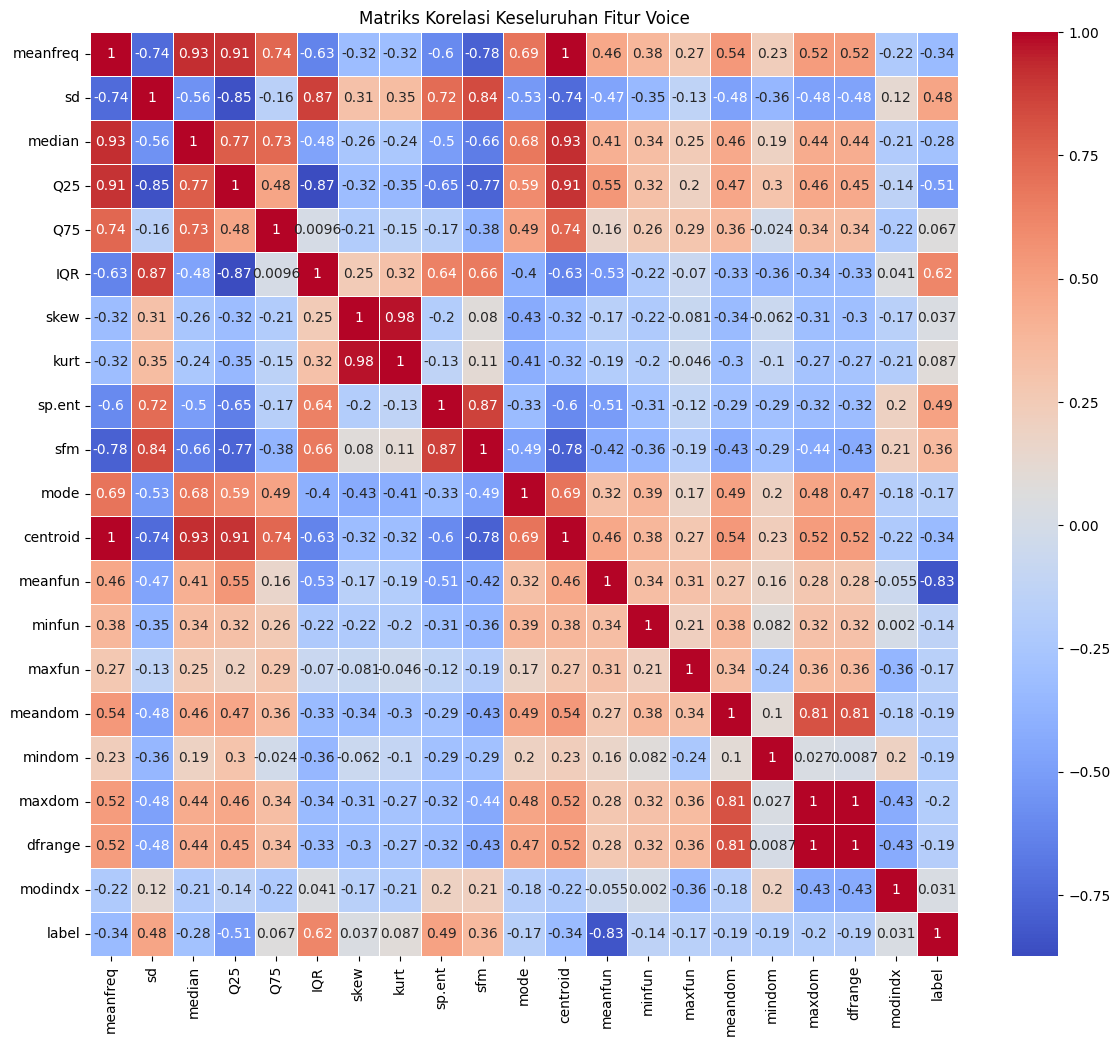

In [13]:
# Konversi label kategorikal (female/male) ke numerik
data_encoded = data.copy()
data_encoded['label'] = data_encoded['label'].map({'female': 0, 'male': 1})

# Menghitung matriks korelasi seluruh fitur
correlation_matrix = data_encoded.corr()

# Menampilkan heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)
plt.title('Matriks Korelasi Keseluruhan Fitur Voice')
plt.show()

Untuk mendapatkan hasil klasifikasi terbaik pada dataset voice.csv, fitur-fitur yang dipilih adalah fitur yang memiliki korelasi paling kuat (baik positif maupun negatif) terhadap label target, serta mengeliminasi fitur yang saling berulang (multikolinearitas tinggi).
1. Daftar Fitur yang Digunakan:
  - meanfun (Mean Fundamental Frequency)<br>
  Memilki korelasi negatif paling dominan terhadap label gender.
  - IQR (Interquartile Range)<br>
  Memiliki korelasi positif yang cukup kuat dengan label.- Q25 (25th Percentile Frequency)<br>
  Menunjukkan korelasi positif yang signifikan.
  - sp.ent (Spectral Entropy)<br>
  Memberikan kontribusi korelasi positif yang membedakan distribusi frekuensi.
  - sd (Standard Deviation)<br>
  Membantu membedakan variasi frekuensi suara.
2. Alasan Pemilihan Fitur
  - Menghindari Multikolinearitas<br>
  Fitur seperti centroid dan meanfreq memiliki korelasi hampir $1.0$ (merah tua linier), sehingga cukup menggunakan salah satunya saja agar model tidak redundan.
  - Memaksimalkan Performa<br>
  Mengurangi fitur yang tidak relevan (seperti modindx atau meandom yang korelasinya mendekati $0$) membuat model kNN bekerja lebih cepat, efisien, dan mengurangi dampak curse of dimensionality tanpa menurunkan akurasi model secara signifikan.

#### 3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

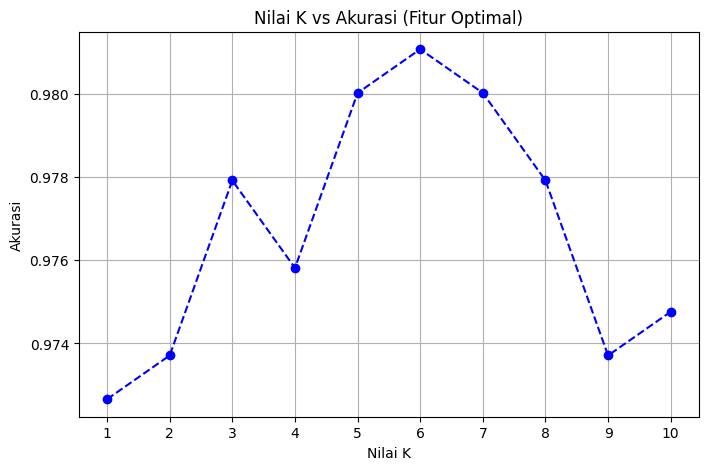

In [14]:
selected_features = ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd']
X_opt = data[selected_features]
y = data['label']

# split data dan standardisasi
X_train_opt, X_test_opt, y_train, y_test = train_test_split(X_opt, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_opt = scaler.fit_transform(X_train_opt)
X_test_opt = scaler.transform(X_test_opt)

# menguji nilai K dari 1 hingga 10
acc_opt = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_opt, y_train)
    acc_opt.append(model.score(X_test_opt, y_test))

# plot grafik Nilai K vs Akurasi
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), acc_opt, marker='o', color='b', linestyle='--')
plt.title('Nilai K vs Akurasi (Fitur Optimal)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Nilai K Terbaik:<br>
Berdasarkan grafik evaluasi nilai K, nilai K terbaik yang direkomendasikan adalah K = 5 (atau K = 6 jika hanya memperhitungkan akurasi data test tertinggi secara mutlak).

Alasan Pemilihan:<br>

- Akurasi Sangat Tinggi<br>
Nilai K = 5 menghasilkan akurasi sebesar 0.980 (98%), hanya selisih sangat tipis dari K = 6.
- Menghindari Perolehan Suara Seri (Tie Vote)<br>
Pada klasifikasi biner (2 kelas: male dan female), lebih disarankan untuk memilih nilai K bernilai ganjil seperti K = 5. Menggunakan K genap (seperti K = 6) berisiko menghasilkan jumlah tetangga yang seimbang (3 male dan 3 female) pada saat memprediksi data baru.<br>
- Keseimbangan Generalisasi<br>
Nilai K = 5 memberikan generalisasi batas keputusan yang stabil, tidak terlalu rentan terhadap noise seperti K = 1, dan tidak terlalu mulus (underfitting) seperti K yang lebih besar.